<a href="https://colab.research.google.com/github/asem87/DEPI-E-Commerce-Customer-Value-Prediction/blob/main/Data_cleaning%26EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Cleaning – Olist E-Commerce
Simple step by step cleaning: missing values, wrong values, duplicates, data types and text, outliers. The clean tables are saved to `data/processed/`.

In [ ]:
import kagglehub
import pandas as pd

# Download latest version
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Path to dataset files: /kaggle/input/brazilian-ecommerce


In [ ]:
import numpy as np

customers      = pd.read_csv(f"{path}/olist_customers_dataset.csv", dtype={"customer_zip_code_prefix": str})
sellers        = pd.read_csv(f"{path}/olist_sellers_dataset.csv", dtype={"seller_zip_code_prefix": str})
orders         = pd.read_csv(f"{path}/olist_orders_dataset.csv")
order_items    = pd.read_csv(f"{path}/olist_order_items_dataset.csv")
order_payments = pd.read_csv(f"{path}/olist_order_payments_dataset.csv")
order_reviews  = pd.read_csv(f"{path}/olist_order_reviews_dataset.csv")
products       = pd.read_csv(f"{path}/olist_products_dataset.csv")
category_translation = pd.read_csv(f"{path}/product_category_name_translation.csv", encoding="utf-8-sig")

In [ ]:
print("customers      ", len(customers))
print("sellers        ", len(sellers))
print("orders         ", len(orders))
print("order_items    ", len(order_items))
print("order_payments ", len(order_payments))
print("order_reviews  ", len(order_reviews))
print("products       ", len(products))
print("category_translation", len(category_translation))

customers       99441
sellers         3095
orders          99441
order_items     112650
order_payments  103886
order_reviews   99224
products        32951
category_translation 71


# 1. Missing values

In [ ]:
print("missing before:", products["product_category_name"].isnull().sum())
products["product_category_name"] = products["product_category_name"].fillna("unknown")
print("missing after :", products["product_category_name"].isnull().sum())

missing before: 610
missing after : 0


In [ ]:
cols = ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]

for col in cols:
    products.loc[products[col] <= 0, col] = np.nan                       # 0 -> missing
    median_by_category = products.groupby("product_category_name")[col].transform("median")
    products[col] = products[col].fillna(median_by_category)             # median of the category
    products[col] = products[col].fillna(products[col].median())         # if the whole category is empty

print(products[cols].isnull().sum())

product_weight_g     0
product_length_cm    0
product_height_cm    0
product_width_cm     0
dtype: int64


In [ ]:
order_reviews["review_comment_title"] = order_reviews["review_comment_title"].replace(r"^\s*$", np.nan, regex=True)
order_reviews["review_comment_message"] = order_reviews["review_comment_message"].replace(r"^\s*$", np.nan, regex=True)

# 2. Wrong values

In [ ]:
bad = (order_payments["payment_type"] == "not_defined") | (order_payments["payment_value"] <= 0) | order_payments["payment_value"].isnull()
print("rows removed:", bad.sum())
order_payments = order_payments[~bad]

rows removed: 9


In [ ]:
print("rows fixed:", (order_payments["payment_installments"] < 1).sum())
order_payments.loc[order_payments["payment_installments"] < 1, "payment_installments"] = 1

rows fixed: 2


In [ ]:
bad = order_items["price"].isnull() | (order_items["price"] <= 0) | (order_items["freight_value"] < 0)
print("rows removed:", bad.sum())
order_items = order_items[~bad]

rows removed: 0


In [ ]:
bad = order_reviews["review_score"].isnull() | (order_reviews["review_score"] < 1) | (order_reviews["review_score"] > 5)
print("rows removed:", bad.sum())
order_reviews = order_reviews[~bad]

rows removed: 0


# 3. Duplicates

In [ ]:
print("customers      ", customers.duplicated().sum())
print("sellers        ", sellers.duplicated().sum())
print("orders         ", orders.duplicated().sum())
print("order_items    ", order_items.duplicated().sum())
print("order_payments ", order_payments.duplicated().sum())
print("order_reviews  ", order_reviews.duplicated().sum())
print("products       ", products.duplicated().sum())
print("category_translation", category_translation.duplicated().sum())

customers      = customers.drop_duplicates()
sellers        = sellers.drop_duplicates()
orders         = orders.drop_duplicates()
order_items    = order_items.drop_duplicates()
order_payments = order_payments.drop_duplicates()
order_reviews  = order_reviews.drop_duplicates()
products       = products.drop_duplicates()
category_translation = category_translation.drop_duplicates()

customers       0
sellers         0
orders          0
order_items     0
order_payments  0
order_reviews   0
products        0
category_translation 0


In [ ]:
customers      = customers.drop_duplicates(subset="customer_id")
sellers        = sellers.drop_duplicates(subset="seller_id")
orders         = orders.drop_duplicates(subset="order_id")
products       = products.drop_duplicates(subset="product_id")
category_translation = category_translation.drop_duplicates(subset="product_category_name")
order_items    = order_items.drop_duplicates(subset=["order_id", "order_item_id"])
order_payments = order_payments.drop_duplicates(subset=["order_id", "payment_sequential"])

In [ ]:
print("extra reviews:", order_reviews["order_id"].duplicated().sum())

order_reviews = order_reviews.sort_values(["order_id", "review_answer_timestamp"])
order_reviews = order_reviews.drop_duplicates(subset="order_id", keep="last")

print("one review per order:", order_reviews["order_id"].is_unique)

extra reviews: 551
one review per order: True


# 4. Data types and text

In [ ]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

order_items["shipping_limit_date"] = pd.to_datetime(order_items["shipping_limit_date"], errors="coerce")
order_reviews["review_creation_date"] = pd.to_datetime(order_reviews["review_creation_date"], errors="coerce")
order_reviews["review_answer_timestamp"] = pd.to_datetime(order_reviews["review_answer_timestamp"], errors="coerce")

In [ ]:
approved_before_purchase  = orders["order_approved_at"] < orders["order_purchase_timestamp"]
delivered_before_purchase = orders["order_delivered_customer_date"] < orders["order_purchase_timestamp"]
carrier_before_purchase   = orders["order_delivered_carrier_date"] < orders["order_purchase_timestamp"]
carrier_after_delivery    = orders["order_delivered_carrier_date"] > orders["order_delivered_customer_date"]

print("approved before purchase :", approved_before_purchase.sum())
print("delivered before purchase:", delivered_before_purchase.sum())
print("carrier before purchase  :", carrier_before_purchase.sum())
print("carrier after delivery   :", carrier_after_delivery.sum())

orders.loc[approved_before_purchase, "order_approved_at"] = pd.NaT
orders.loc[delivered_before_purchase, "order_delivered_customer_date"] = pd.NaT
orders.loc[carrier_before_purchase | carrier_after_delivery, "order_delivered_carrier_date"] = pd.NaT

approved before purchase : 0
delivered before purchase: 0
carrier before purchase  : 166
carrier after delivery   : 23


In [ ]:
customers["customer_city"]  = customers["customer_city"].str.strip().str.lower()
customers["customer_state"] = customers["customer_state"].str.strip().str.upper()
sellers["seller_city"]      = sellers["seller_city"].str.strip().str.lower()
sellers["seller_state"]     = sellers["seller_state"].str.strip().str.upper()
orders["order_status"]      = orders["order_status"].str.strip().str.lower()
order_payments["payment_type"] = order_payments["payment_type"].str.strip().str.lower()

customers["customer_zip_code_prefix"] = customers["customer_zip_code_prefix"].str.strip().str.zfill(5)
sellers["seller_zip_code_prefix"]     = sellers["seller_zip_code_prefix"].str.strip().str.zfill(5)

In [ ]:
products = products.rename(columns={"product_name_lenght": "product_name_length",
                                    "product_description_lenght": "product_description_length"})

In [ ]:
new_rows = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos", "unknown"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_and_food_preparers", "unknown"],
})
category_translation = pd.concat([category_translation, new_rows], ignore_index=True)
category_translation = category_translation.drop_duplicates(subset="product_category_name")

In [ ]:
orders = orders[orders["customer_id"].isin(customers["customer_id"])]

order_items = order_items[order_items["order_id"].isin(orders["order_id"])]
order_items = order_items[order_items["product_id"].isin(products["product_id"])]
order_items = order_items[order_items["seller_id"].isin(sellers["seller_id"])]

order_payments = order_payments[order_payments["order_id"].isin(orders["order_id"])]
order_reviews  = order_reviews[order_reviews["order_id"].isin(orders["order_id"])]

# 5. Outliers

In [ ]:
for name, values in [("price", order_items["price"]),
                     ("freight_value", order_items["freight_value"]),
                     ("payment_value", order_payments["payment_value"])]:
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR
    count = (values > upper).sum()
    print(f"{name:15s} upper limit = {upper:8.2f}   outliers = {count}   max = {values.max():.2f}")

price           upper limit =   277.40   outliers = 8427   max = 6735.00
freight_value   upper limit =    33.25   outliers = 11613   max = 409.68
payment_value   upper limit =   344.37   outliers = 7981   max = 13664.08


In [ ]:
print("orders -> customers  :", orders["customer_id"].isin(customers["customer_id"]).all())
print("items -> orders      :", order_items["order_id"].isin(orders["order_id"]).all())
print("items -> products    :", order_items["product_id"].isin(products["product_id"]).all())
print("items -> sellers     :", order_items["seller_id"].isin(sellers["seller_id"]).all())
print("payments -> orders   :", order_payments["order_id"].isin(orders["order_id"]).all())
print("reviews -> orders    :", order_reviews["order_id"].isin(orders["order_id"]).all())
print("products -> category :", products["product_category_name"].isin(category_translation["product_category_name"]).all())
print("one review per order :", order_reviews["order_id"].is_unique)

orders -> customers  : True
items -> orders      : True
items -> products    : True
items -> sellers     : True
payments -> orders   : True
reviews -> orders    : True
products -> category : True
one review per order : True


In [ ]:
print("customers      ", len(customers))
print("sellers        ", len(sellers))
print("orders         ", len(orders))
print("order_items    ", len(order_items))
print("order_payments ", len(order_payments))
print("order_reviews  ", len(order_reviews))
print("products       ", len(products))
print("category_translation", len(category_translation))

customers       99441
sellers         3095
orders          99441
order_items     112650
order_payments  103877
order_reviews   98673
products        32951
category_translation 74


In [ ]:
import os
os.makedirs("data/processed", exist_ok=True)

for col in date_cols:
    orders[col] = orders[col].dt.strftime("%Y-%m-%d %H:%M:%S")
order_items["shipping_limit_date"] = order_items["shipping_limit_date"].dt.strftime("%Y-%m-%d %H:%M:%S")
order_reviews["review_creation_date"] = order_reviews["review_creation_date"].dt.strftime("%Y-%m-%d %H:%M:%S")
order_reviews["review_answer_timestamp"] = order_reviews["review_answer_timestamp"].dt.strftime("%Y-%m-%d %H:%M:%S")

customers.to_csv("data/processed/customers.csv", index=False)
sellers.to_csv("data/processed/sellers.csv", index=False)
orders.to_csv("data/processed/orders.csv", index=False)
order_items.to_csv("data/processed/order_items.csv", index=False)
order_payments.to_csv("data/processed/order_payments.csv", index=False)
order_reviews.to_csv("data/processed/order_reviews.csv", index=False)
products.to_csv("data/processed/products.csv", index=False)
category_translation.to_csv("data/processed/category_translation.csv", index=False)

print("saved in data/processed/")

saved in data/processed/


In [ ]:
# Colab only: download the clean files as a zip (does nothing on your own computer)
try:
    import shutil
    from google.colab import files
    shutil.make_archive("processed_data", "zip", "data/processed")
    files.download("processed_data.zip")
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# EDA




In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
pay_agg = order_payments.groupby("order_id").agg(
    payment_total=("payment_value", "sum"),
    max_installments=("payment_installments", "max"),
).reset_index()

main_pay = (order_payments.sort_values("payment_value", ascending=False)
            .drop_duplicates("order_id")[["order_id", "payment_type"]]
            .rename(columns={"payment_type": "main_payment_type"}))

In [ ]:
items_agg = order_items.groupby("order_id").agg(
    items_total=("price", "sum"),
    freight_total=("freight_value", "sum"),
    n_items=("order_item_id", "count"),
).reset_index()


In [ ]:
order_df = (
    orders
    .merge(customers[["customer_id", "customer_unique_id", "customer_city", "customer_state"]],
           on="customer_id", how="left")
    .merge(items_agg, on="order_id", how="left")
    .merge(pay_agg, on="order_id", how="left")
    .merge(main_pay, on="order_id", how="left")
    .merge(order_reviews[["order_id", "review_score"]], on="order_id", how="left")
)


In [ ]:
# Convert date columns back to datetime first, as they were formatted to strings earlier
date_cols = ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    order_df[col] = pd.to_datetime(order_df[col], errors="coerce")

order_df["month"] = order_df["order_purchase_timestamp"].dt.to_period("M")
order_df["day"]   = order_df["order_purchase_timestamp"].dt.day_name()
order_df["hour"]  = order_df["order_purchase_timestamp"].dt.hour

order_df["delivery_days"] = (order_df["order_delivered_customer_date"]
                             - order_df["order_purchase_timestamp"]).dt.days
order_df["estimated_days"] = (order_df["order_estimated_delivery_date"]
                              - order_df["order_purchase_timestamp"]).dt.days
order_df["delay_days"] = (order_df["order_delivered_customer_date"]
                          - order_df["order_estimated_delivery_date"]).dt.days

order_df["is_late"] = (order_df["order_delivered_customer_date"]
                       > order_df["order_estimated_delivery_date"]).astype(float)
order_df.loc[order_df["order_delivered_customer_date"].isna(), "is_late"] = np.nan

In [ ]:
products_en = products.merge(category_translation, on="product_category_name", how="left")

items_full = (
    order_items
    .merge(products_en[["product_id", "product_category_name_english",
                        "product_weight_g", "product_photos_qty"]], on="product_id", how="left")
    .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")
    .merge(orders[["order_id", "order_status", "order_purchase_timestamp"]], on="order_id", how="left")
)

In [ ]:
valid_orders = order_df[~order_df["order_status"].isin(["canceled", "unavailable"])]
valid_items  = items_full[~items_full["order_status"].isin(["canceled", "unavailable"])]

print("order_df:", order_df.shape, "| items_full:", items_full.shape)
order_df.head()

order_df: (99441, 25) | items_full: (112650, 13)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,...,max_installments,main_payment_type,review_score,month,day,hour,delivery_days,estimated_days,delay_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,sao paulo,...,1.0,voucher,4.0,2017-10,Monday,10,8.0,15,-8.0,0.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,barreiras,...,1.0,boleto,4.0,2018-07,Tuesday,20,13.0,19,-6.0,0.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,...,3.0,credit_card,5.0,2018-08,Wednesday,8,9.0,26,-18.0,0.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,...,1.0,credit_card,5.0,2017-11,Saturday,19,13.0,26,-13.0,0.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,...,1.0,credit_card,5.0,2018-02,Tuesday,21,2.0,12,-10.0,0.0


Order Status


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


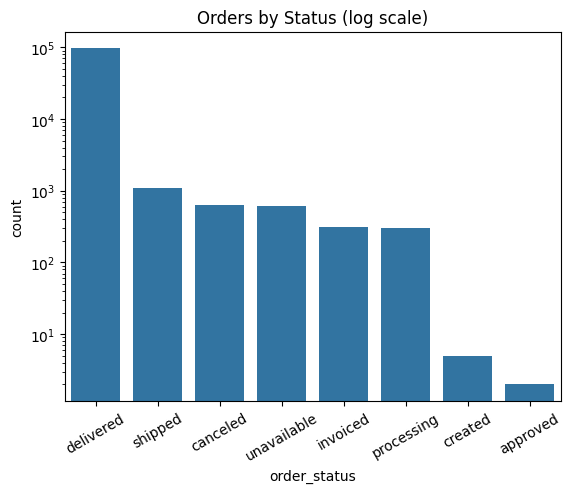

In [ ]:
print(order_df["order_status"].value_counts())

sns.countplot(data=order_df, x="order_status",
              order=order_df["order_status"].value_counts().index)
plt.yscale("log")
plt.title("Orders by Status (log scale)")
plt.xticks(rotation=30)
plt.show()

Monthly orders and revenue

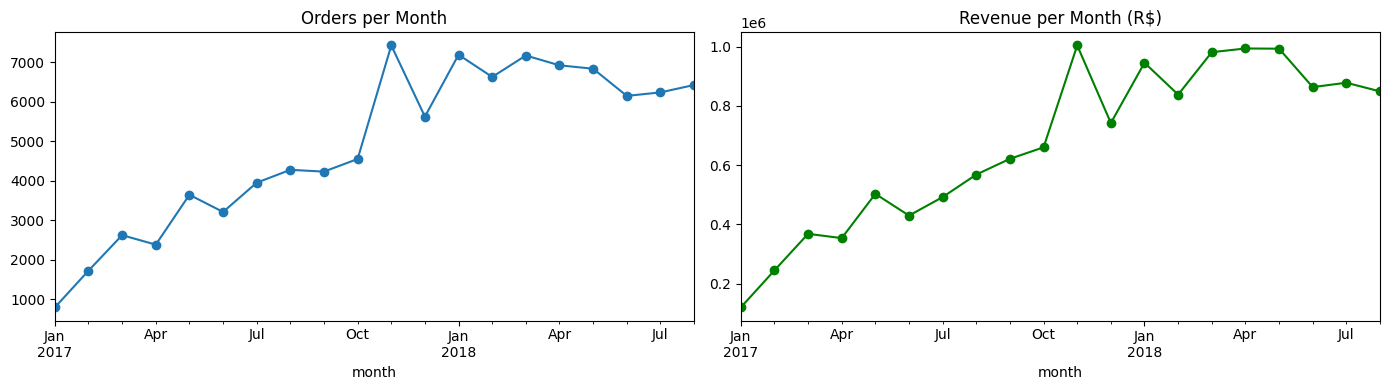

In [ ]:
monthly = valid_orders.groupby("month").agg(
    orders=("order_id", "count"),
    revenue=("items_total", "sum"),
)
monthly = monthly.loc["2017-01":"2018-08"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
monthly["orders"].plot(marker="o", ax=axes[0], title="Orders per Month")
monthly["revenue"].plot(marker="o", color="green", ax=axes[1], title="Revenue per Month (R$)")
plt.tight_layout()
plt.show()

The most popular days and times for shopping

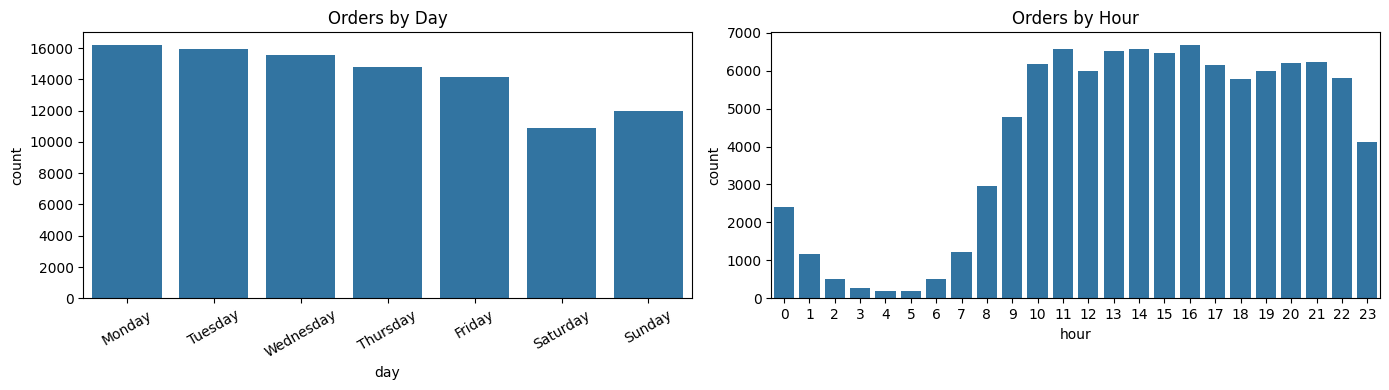

In [ ]:
order_days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=order_df, x="day", order=order_days, ax=axes[0])
axes[0].set_title("Orders by Day")
axes[0].tick_params(axis="x", rotation=30)
sns.countplot(data=order_df, x="hour", ax=axes[1])
axes[1].set_title("Orders by Hour")
plt.tight_layout()
plt.show()

customar states & city

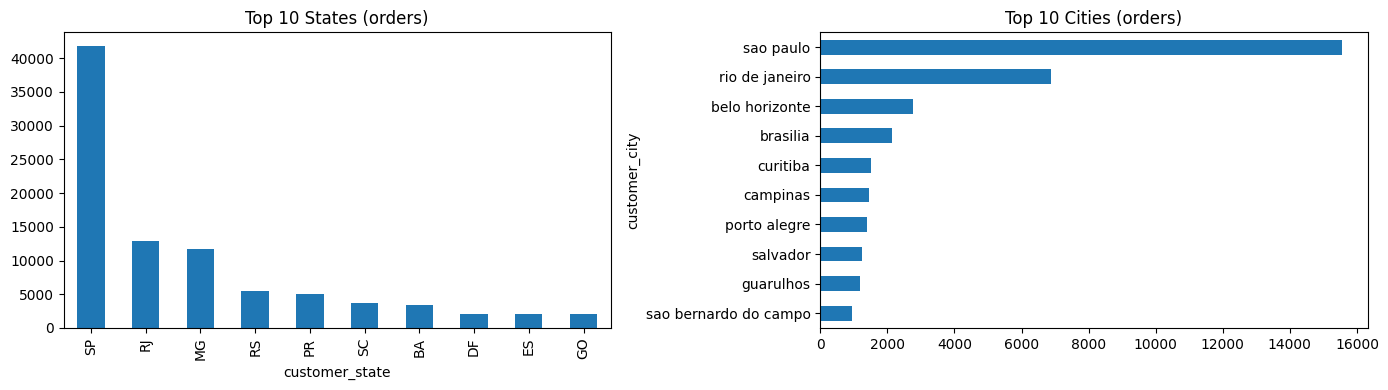

TOP 3 states:
 customer_state
SP    42.0
RJ    12.9
MG    11.7
Name: proportion, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
order_df["customer_state"].value_counts().head(10).plot(kind="bar", ax=axes[0],
                                                        title="Top 10 States (orders)")
order_df["customer_city"].value_counts().head(10).sort_values().plot(kind="barh", ax=axes[1],
                                                                     title="Top 10 Cities (orders)")
plt.tight_layout()
plt.show()

state_share = order_df["customer_state"].value_counts(normalize=True).head(3) * 100
print("TOP 3 states:\n", state_share.round(1))


In [ ]:
customer_df = valid_orders.groupby("customer_unique_id").agg(
    orders_count=("order_id", "nunique"),
    total_spend=("payment_total", "sum"),
    avg_order_value=("payment_total", "mean"),
    avg_review=("review_score", "mean"),
    first_purchase=("order_purchase_timestamp", "min"),
    last_purchase=("order_purchase_timestamp", "max"),
).reset_index()


number of orders & total spend

number of real customers 94990
persent of Repeated customers 3.04 %
orders_count
1    92102
2     2652
3      188
4       29
5        9
Name: count, dtype: int64


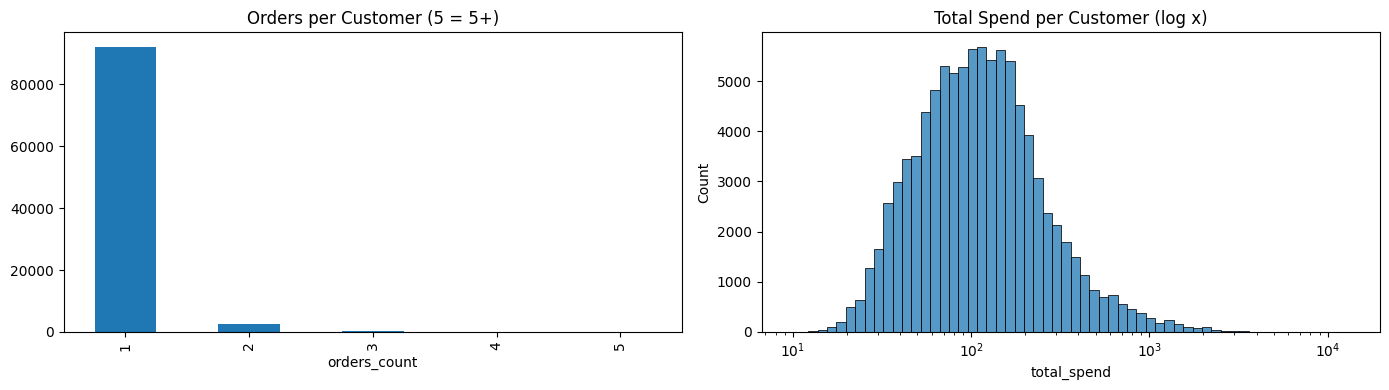

In [ ]:
print("number of real customers", len(customer_df))
print("persent of Repeated customers", round((customer_df["orders_count"] > 1).mean() * 100, 2), "%")
print(customer_df["orders_count"].value_counts().head())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
customer_df["orders_count"].clip(upper=5).value_counts().sort_index().plot(
    kind="bar", ax=axes[0], title="Orders per Customer (5 = 5+)")
sns.histplot(customer_df["total_spend"], bins=60, log_scale=True, ax=axes[1])
axes[1].set_title("Total Spend per Customer (log x)")
plt.tight_layout()
plt.show()

In [ ]:
spend = customer_df["total_spend"].sort_values(ascending=False)
top10 = spend.head(int(len(spend) * 0.10)).sum() / spend.sum()
print(f"The top 10% of customers make up {top10:.1%} of total revenue")

The top 10% of customers make up 38.3% of total revenue


Categories

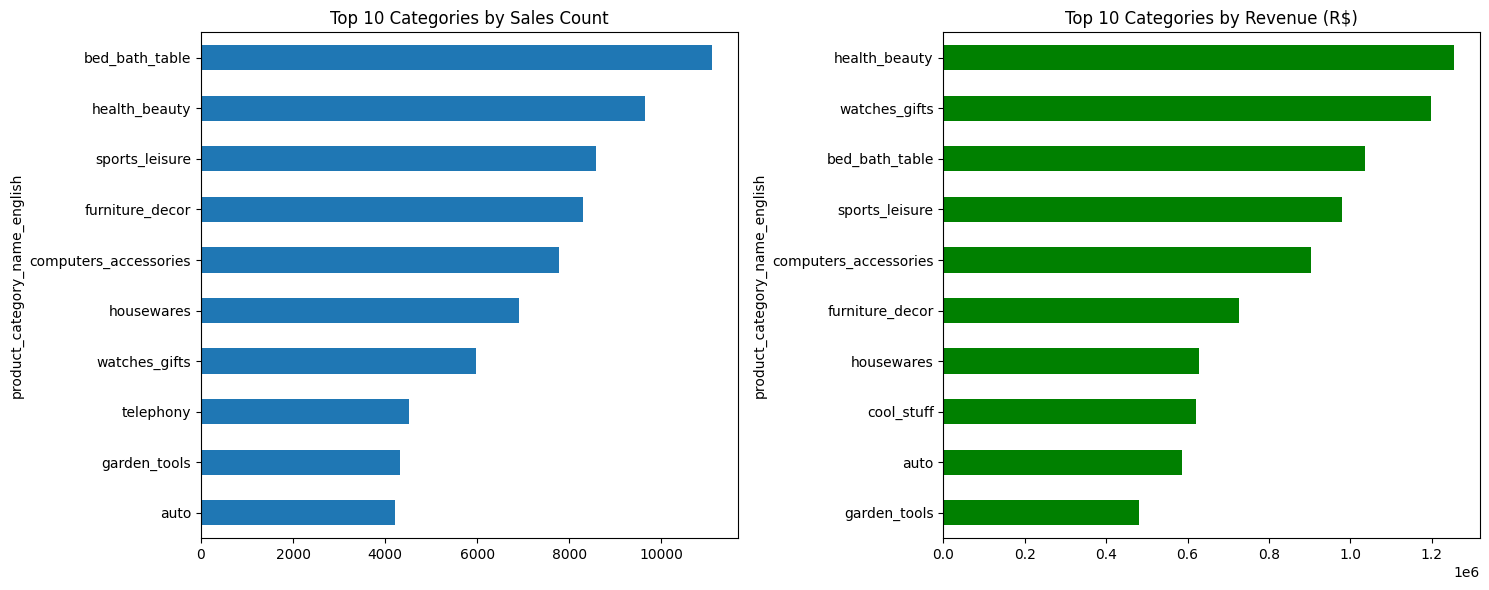

In [ ]:
cat = valid_items.groupby("product_category_name_english").agg(
    sales=("order_id", "count"),
    revenue=("price", "sum"),
    avg_price=("price", "mean"),
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cat["sales"].nlargest(10).sort_values().plot(kind="barh", ax=axes[0],
                                             title="Top 10 Categories by Sales Count")
cat["revenue"].nlargest(10).sort_values().plot(kind="barh", color="green", ax=axes[1],
                                               title="Top 10 Categories by Revenue (R$)")
plt.tight_layout()
plt.show()



price & freight value

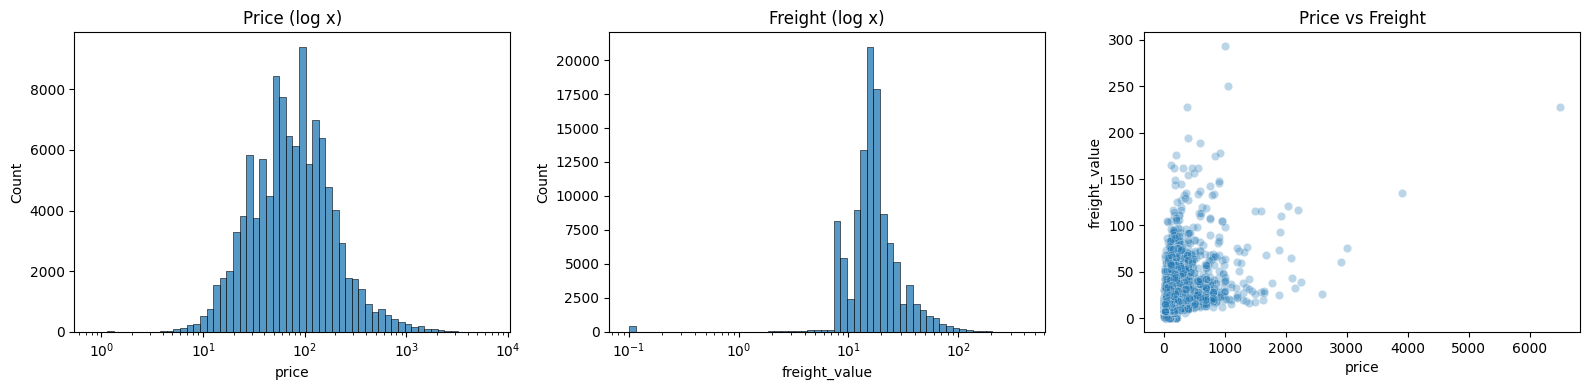

               price  freight_value
count  112650.000000  112650.000000
mean      120.653739      19.990320
std       183.633928      15.806405
min         0.850000       0.000000
25%        39.900000      13.080000
50%        74.990000      16.260000
75%       134.900000      21.150000
max      6735.000000     409.680000


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(order_items["price"], bins=60, log_scale=True, ax=axes[0])
axes[0].set_title("Price (log x)")
sns.histplot(order_items["freight_value"].clip(lower=0.1), bins=60, log_scale=True, ax=axes[1])
axes[1].set_title("Freight (log x)")
sns.scatterplot(data=order_items.sample(10000, random_state=1),
                x="price", y="freight_value", alpha=0.3, ax=axes[2])
axes[2].set_title("Price vs Freight")
plt.tight_layout()
plt.show()

print(order_items[["price", "freight_value"]].describe())

payment methods

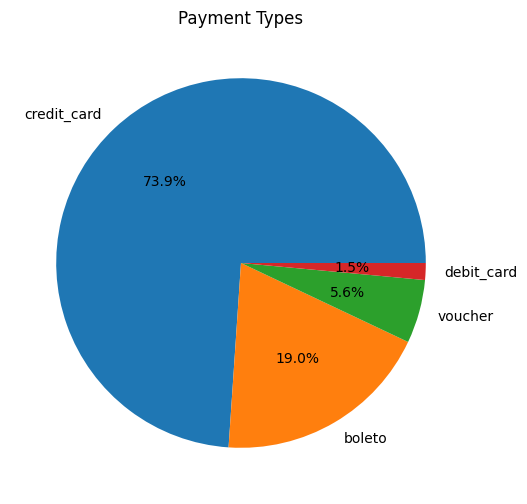

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
order_payments["payment_type"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=ax)
ax.set_title("Payment Types")
ax.set_ylabel("")
plt.show()

Rating

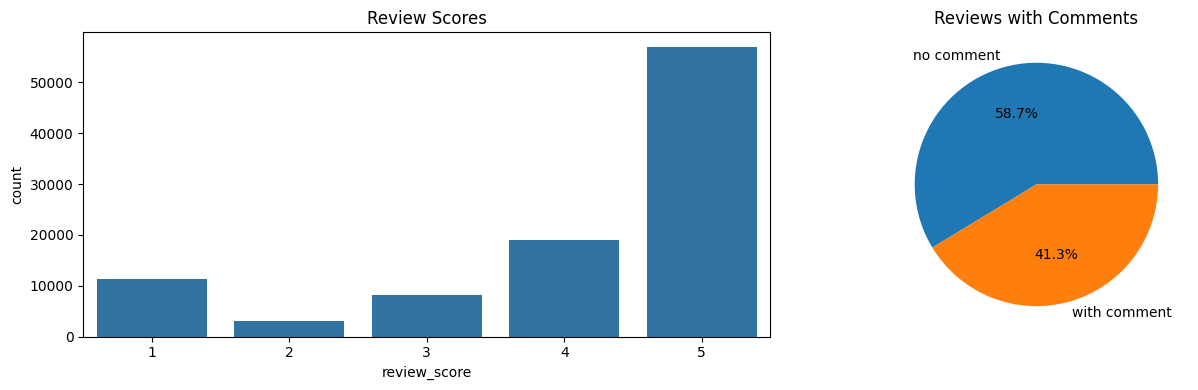

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=order_reviews, x="review_score", ax=axes[0])
axes[0].set_title("Review Scores")

has_comment = order_reviews["review_comment_message"].notna()
has_comment.value_counts().rename({True: "with comment", False: "no comment"}).plot(
    kind="pie", autopct="%1.1f%%", ax=axes[1])
axes[1].set_title("Reviews with Comments")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

Delivery

       delivery_days  estimated_days    delay_days
count   96476.000000    96476.000000  96476.000000
mean       12.094086       23.374228    -11.876881
std         9.551746        8.760830     10.183854
min         0.000000        2.000000   -147.000000
25%         6.000000       18.000000    -17.000000
50%        10.000000       23.000000    -12.000000
75%        15.000000       28.000000     -7.000000
max       209.000000      155.000000    188.000000
Rate of late orders: 8.11 %


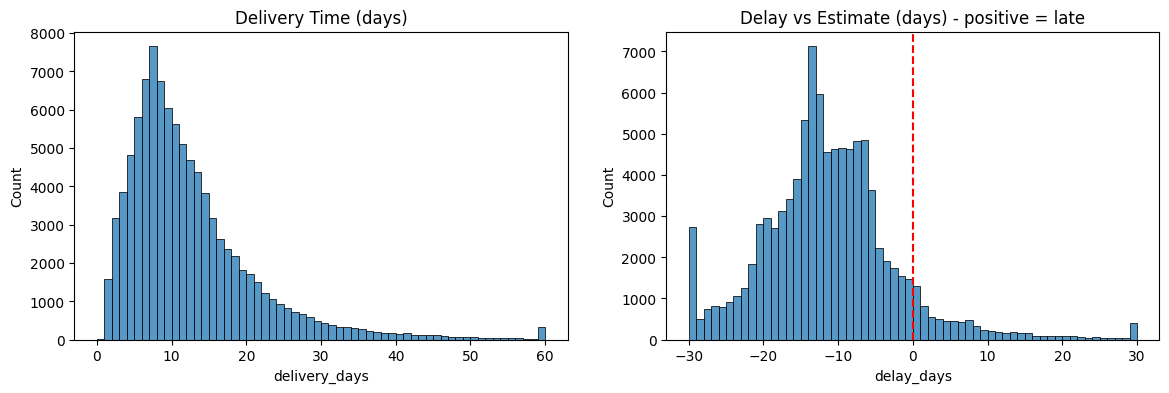

In [ ]:
delivered = order_df[order_df["delivery_days"].notna()]
print(delivered[["delivery_days", "estimated_days", "delay_days"]].describe())
print("Rate of late orders:", round(delivered["is_late"].mean() * 100, 2), "%")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(delivered["delivery_days"].clip(upper=60), bins=60, ax=axes[0])
axes[0].set_title("Delivery Time (days)")
sns.histplot(delivered["delay_days"].clip(-30, 30), bins=60, ax=axes[1])
axes[1].axvline(0, color="red", ls="--")
axes[1].set_title("Delay vs Estimate (days) - positive = late")
plt.show()

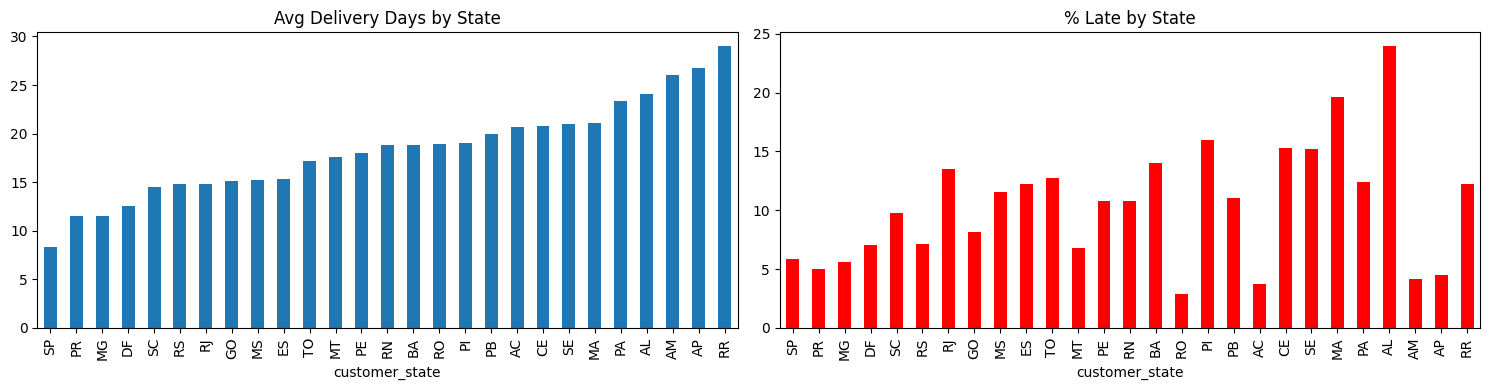

In [ ]:
state_delivery = (delivered.groupby("customer_state")
                  .agg(avg_days=("delivery_days", "mean"), late_pct=("is_late", "mean"))
                  .sort_values("avg_days"))
state_delivery["late_pct"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
state_delivery["avg_days"].plot(kind="bar", ax=axes[0], title="Avg Delivery Days by State")
state_delivery["late_pct"].plot(kind="bar", color="red", ax=axes[1], title="% Late by State")
plt.tight_layout()
plt.show()

n_items
1.0    88863
2.0     7516
3.0     1322
4.0      505
5.0      204
Name: count, dtype: int64


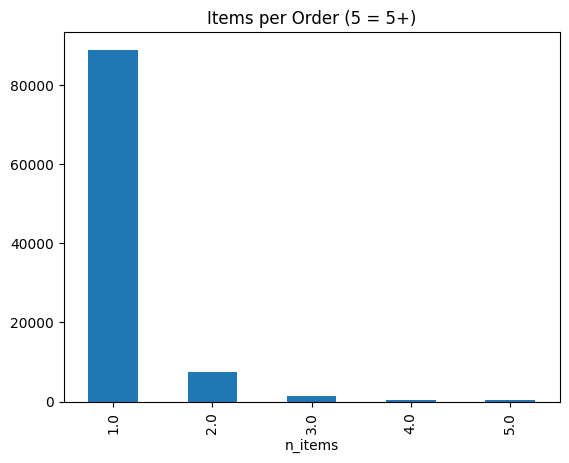

In [ ]:
print(order_df["n_items"].value_counts().head())

order_df["n_items"].clip(upper=5).value_counts().sort_index().plot(
    kind="bar", title="Items per Order (5 = 5+)")
plt.show()

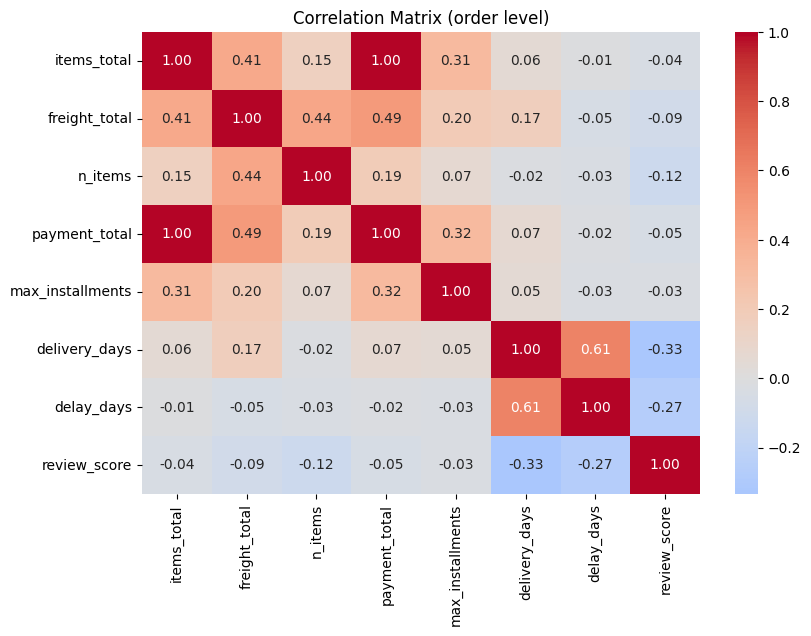

In [ ]:
corr_cols = ["items_total", "freight_total", "n_items", "payment_total",
             "max_installments", "delivery_days", "delay_days", "review_score"]

plt.figure(figsize=(9, 6))
sns.heatmap(order_df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix (order level)")
plt.show()